# Estimating ticket resolution time

Synthetic support tickets. The aim is to practise the modelling choices, not to describe a real team.

Predict `resolution_hours` when a ticket arrives. Compare a mean baseline, linear regression, polynomial regression, Ridge and Lasso.

In [1]:
# Imports for the lab.
# pandas/numpy for the table, sklearn for the models, matplotlib for the plots.
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Task 1: load the csv and look at it
df = pd.read_csv("lab_ticket_resolution.csv")

print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nDescriptive statistics:")
print(df.describe(include="all").round(2))  # rounded so the table is readable
print("\nMissing values:")
print(df.isna().sum())

df.head()

Shape: (240, 6)

Data types:
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

Descriptive statistics:
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240            240.00         240.00                 240.00   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN              5.49          54.82                   6.11   
std          NaN              2.98          26.15                   3.39   
min          NaN              1.00           1.00                   0.50   
25%          NaN              3.00          33.00                   3.30   
50%          NaN              5.50          54.00 

,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


240 tickets, 6 columns, and nothing missing. `resolution_hours` runs from 0.5 to 42.5, average about 19.4. `complexity_score` is on a 1-10 scale. About 23% of the tickets were reopened (`reopened` mean 0.23). Team experience is between 0.5 and 12 years.

The table is clean. The real decision is which columns I am allowed to use.

## Task 2: Target and features

In [2]:
# Task 2: y is resolution time. X is only what we would know when the ticket arrives.
target = "resolution_hours"
features = ["complexity_score", "team_experience_years"]

excluded = {
    "ticket_id": "just an id, not a feature",
    "lines_changed": "only known after the fix is written, so it would leak",
    "reopened": "only known after the ticket was already resolved, so it would leak",
}

X = df[features]
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", features)
print("\nLeft out:")
for col, reason in excluded.items():
    print(f"  {col}: {reason}")

# correlation with the target, to see which columns are tied to the outcome
print("\nCorrelation with resolution_hours:")
print(df.drop(columns="ticket_id").corr()["resolution_hours"].round(3))

X shape: (240, 2)
y shape: (240,)
Features: ['complexity_score', 'team_experience_years']

Left out:
  ticket_id: just an id, not a feature
  lines_changed: only known after the fix is written, so it would leak
  reopened: only known after the ticket was already resolved, so it would leak

Correlation with resolution_hours:
complexity_score         0.918
lines_changed            0.847
team_experience_years   -0.175
reopened                 0.301
resolution_hours         1.000
Name: resolution_hours, dtype: float64


### Which columns are known at prediction time

I want the estimate when the ticket comes in, before anyone starts the fix. A column only counts if it would already be filled in.

**Target:** `resolution_hours`.

**Used:**
- `complexity_score`, set at triage, on a 1-10 scale.
- `team_experience_years`, the experience of the team the ticket is given to. That is known once it is routed, still before the work.

**Left out:**
- `ticket_id` is only a label. It doesn't describe the work, and a model could memorise individual rows from it.
- `lines_changed` is how many lines were edited during the fix. That count does not exist yet. It also moves with the target (correlation about 0.85), so putting it in X would make the test score look better than a real deployment.
- `reopened` is only known after the ticket was resolved and came back. Same timing problem. Its correlation with the target is weaker (about 0.30), but it still isn't available up front.

`complexity_score` on its own correlates about 0.92 with resolution time, so I already expect it to do most of the work. Team experience correlates about -0.18, a smaller effect in the sensible direction.

If the model was meant to run after the patch was written, `lines_changed` could be fair game. I used the earlier moment, when the ticket arrives. X is (240, 2).

## Task 3: Train/test split

In [3]:
# Task 3: hold out 20% as a test set.
# random_state=42 keeps the split the same every run.
# The test rows are not used to pick degree or alpha. That is done with CV on the training set.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print("Mean resolution_hours -> train:", round(y_train.mean(), 2),
      "| test:", round(y_test.mean(), 2))

X_train: (192, 2) | X_test: (48, 2)
y_train: (192,) | y_test: (48,)
Mean resolution_hours -> train: 19.06 | test: 20.58


## Task 4: Baseline

In [4]:
# MAE, RMSE and R2 on the TEST set. Stored so the last cell can show one table.
# MAE  = average absolute error, in hours.
# RMSE = sqrt of the average squared error, in hours. Big misses count more.
# R2   = share of variance explained. 1 is perfect, 0 is no better than the test mean.
results = []

def evaluate(name, model):
    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    results.append({"model": name, "MAE": mae, "RMSE": rmse, "R2": r2})
    print(f"{name}: MAE = {mae:.3f} | RMSE = {rmse:.3f} | R2 = {r2:.3f}")

# Always predicts the training mean. Ignores both features.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

print("Baseline always predicts:", round(float(baseline.constant_.ravel()[0]), 2), "hours")
evaluate("Mean baseline", baseline)

Baseline always predicts: 19.06 hours
Mean baseline: MAE = 9.114 | RMSE = 10.598 | R2 = -0.021


**Q10. Why keep a mean baseline if it ignores the features?**

It is the number the other models have to beat. The baseline always says 19.06 hours, the training average, and on the test set that is off by about 9.1 hours (MAE 9.114, RMSE 10.598). If linear regression or a polynomial can't do clearly better than that, the features are not helping and the extra model is wasted.

It also makes the later errors readable. An MAE of 2.9 hours doesn't mean much alone. Next to 9.1 hours it is a large drop.

R2 is slightly negative (-0.021) because the test tickets are a bit slower on average than the training tickets (20.58 vs 19.06). Guessing the training mean is a little worse than guessing the test mean. That is what a negative R2 means here.

## Task 5: Linear regression

In [5]:
# Task 5: resolution_hours = intercept + w1*complexity_score + w2*team_experience_years
lin = LinearRegression()
lin.fit(X_train, y_train)

print("Intercept:", round(lin.intercept_, 3))
for name, coef in zip(features, lin.coef_):
    print(f"  {name}: {coef:.3f}")

evaluate("Linear regression", lin)

# signed error: positive means the ticket took longer than we predicted
lin_error = y_test.to_numpy() - lin.predict(X_test)
print("Mean signed error on test (actual - predicted):", round(float(lin_error.mean()), 3))

Intercept:

 4.249
  complexity_score: 3.080
  team_experience_years: -0.318
Linear regression: MAE = 2.906 | RMSE = 3.572 | R2 = 0.884
Mean signed error on test (actual - predicted): 0.699


### Linear regression

| Model | MAE | RMSE | R2 |
|---|---|---|---|
| Mean baseline | 9.114 | 10.598 | -0.021 |
| Linear regression | 2.906 | 3.572 | 0.884 |

Each extra complexity point adds about 3.08 hours, holding experience fixed. Each extra year of team experience takes off about 0.32 hours. Both signs make sense. Most of the fit is complexity, which matches the 0.92 correlation. Experience is a smaller slope.

The intercept is about 4.25 hours. That is the prediction when both features are 0, which is not a real ticket, so the slopes are the part worth quoting.

On the test set the predictions are low by about 0.70 hours on average. That lines up with the test tickets being a bit slower than the training ones.

R2 of 0.88 means the two columns explain most of the variation in the 48 test tickets. This is the error the other models have to beat: MAE 2.906, RMSE 3.572.

## Task 6: Polynomial regression

In [6]:
# Task 6: polynomial terms, then scale, then linear regression, in one pipeline.
# Degree 2 adds squares and the complexity*experience product.
# The scaler sits inside the pipeline so each CV fold fits it on its own training rows only.

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def cv_mean(model, scoring):
    scores = cross_val_score(model, X_train, y_train, cv=kf, scoring=scoring)
    if scoring.startswith("neg_"):
        return -scores.mean()
    return scores.mean()

cv_table = []

def add_cv_row(name, model):
    cv_table.append({
        "model": name,
        "CV MAE": cv_mean(model, "neg_mean_absolute_error"),
        "CV RMSE": cv_mean(model, "neg_root_mean_squared_error"),
        "CV R2": cv_mean(model, "r2"),
    })

add_cv_row("Linear (degree 1)", LinearRegression())

poly_models = {}
for degree in [2, 3]:
    pipe = make_pipeline(
        PolynomialFeatures(degree, include_bias=False),
        StandardScaler(),
        LinearRegression(),
    )
    add_cv_row(f"Polynomial (degree {degree})", pipe)
    poly_models[degree] = pipe

display(pd.DataFrame(cv_table).round(3))

# Fit on the full training set and record test metrics.
# The degree was compared with the CV table above, not with these test numbers.
for degree, pipe in poly_models.items():
    pipe.fit(X_train, y_train)
    print(f"degree {degree}: {pipe.named_steps['linearregression'].coef_.size} coefficients")
    evaluate(f"Polynomial (degree {degree})", pipe)

,model,CV MAE,CV RMSE,CV R2
0,Linear (degree 1),3.168,3.909,0.838
1,Polynomial (degree 2),3.131,3.832,0.844
2,Polynomial (degree 3),3.162,3.877,0.841


degree 2: 5 coefficients
Polynomial (degree 2): MAE = 3.020 | RMSE = 3.741 | R2 = 0.873
degree 3: 9 coefficients
Polynomial (degree 3): MAE = 3.140 | RMSE = 3.949 | R2 = 0.858


**Q12. Did polynomial features help, and is there overfitting?**

On cross-validation, degree 2 is only a little better than a straight line: CV MAE 3.131 against 3.168, CV RMSE 3.832 against 3.909. Degree 3 does not improve on degree 2 (CV MAE 3.162, CV RMSE 3.877).

I would not switch to degree 2 for about 0.04 hours of CV MAE. That is noise next to a 3 hour error, and degree 3 moving the wrong way is the overfitting sign: 9 coefficients instead of 2, a CV score that is no better, and a worse test MAE (3.140 for degree 3, 3.020 for degree 2, 2.906 for linear). The test numbers agree with staying linear, but I didn't use them to pick the degree.

The residual plot below also has no curve that a squared term would be needed for.

## Task 7: Ridge and Lasso

In [7]:
# Task 7: Ridge (L2) and Lasso (L1), each scaled.
# alpha is the penalty. Larger alpha shrinks the coefficients more.
# Pick alpha with the same 5 training folds. Do not look at the test set for this.
alphas = [0.001, 0.01, 0.1, 1, 10, 100]

cv_alpha = {}
for name, Model in [("Ridge", Ridge), ("Lasso", Lasso)]:
    cv_alpha[name] = {}
    for alpha in alphas:
        pipe = make_pipeline(StandardScaler(), Model(alpha=alpha, max_iter=100000))
        cv_alpha[name][alpha] = cv_mean(pipe, "neg_root_mean_squared_error")

print("CV RMSE by alpha (training folds only):")
display(pd.DataFrame(cv_alpha).round(4))

chosen = {}
for name, Model in [("Ridge", Ridge), ("Lasso", Lasso)]:
    best_alpha = min(cv_alpha[name], key=cv_alpha[name].get)
    chosen[name] = best_alpha
    model = make_pipeline(StandardScaler(), Model(alpha=best_alpha, max_iter=100000))
    model.fit(X_train, y_train)
    coefs = model.named_steps[name.lower()].coef_
    print(f"\n{name}: alpha = {best_alpha}")
    print("  scaled coefficients:", [round(float(c), 3) for c in coefs])
    evaluate(name, model)

# Same two features, scaled, with no penalty, so the coefficients can be compared.
scaled_lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
print("\nLinear regression, scaled coefficients:",
      [round(float(c), 3) for c in scaled_lin.named_steps["linearregression"].coef_])

CV RMSE by alpha (training folds only):


,Ridge,Lasso
0.001,3.9092,3.9093
0.010,3.9092,3.9093
0.100,3.9092,3.9122
1.000,3.9092,4.1408
10.000,3.9439,9.8839
100.000,5.2922,9.8839



Ridge: alpha = 0.1
  scaled coefficients: [8.99, -1.077]
Ridge: MAE = 2.906 | RMSE = 3.572 | R2 = 0.884

Lasso: alpha = 0.001
  scaled coefficients: [8.994, -1.077]
Lasso: MAE = 2.906 | RMSE = 3.572 | R2 = 0.884

Linear regression, scaled coefficients: [8.995, -1.078]


In [8]:
# Same penalties on the degree-3 model (9 terms). This is where shrinking should matter,
# because the plain degree-3 fit was the one that got worse.
poly3_alpha = {}
for name, Model in [("Ridge", Ridge), ("Lasso", Lasso)]:
    poly3_alpha[name] = {}
    for alpha in alphas:
        pipe = make_pipeline(
            PolynomialFeatures(3, include_bias=False),
            StandardScaler(),
            Model(alpha=alpha, max_iter=100000),
        )
        poly3_alpha[name][alpha] = cv_mean(pipe, "neg_root_mean_squared_error")

print("Degree 3, CV RMSE by alpha:")
display(pd.DataFrame(poly3_alpha).round(3))

raw3 = make_pipeline(
    PolynomialFeatures(3, include_bias=False),
    StandardScaler(),
    LinearRegression(),
).fit(X_train, y_train)
raw_coefs = raw3.named_steps["linearregression"].coef_
print("Degree 3, no penalty. Largest |coefficient|:", round(float(np.max(np.abs(raw_coefs))), 3))
print("  coefficients:", [round(float(c), 3) for c in raw_coefs])

poly3_chosen = {}
for name, Model in [("Ridge", Ridge), ("Lasso", Lasso)]:
    best_alpha = min(poly3_alpha[name], key=poly3_alpha[name].get)
    poly3_chosen[name] = best_alpha
    model = make_pipeline(
        PolynomialFeatures(3, include_bias=False),
        StandardScaler(),
        Model(alpha=best_alpha, max_iter=100000),
    )
    model.fit(X_train, y_train)
    coefs = model.named_steps[name.lower()].coef_
    n_zero = int(np.sum(np.abs(coefs) < 1e-8))
    print(f"\nDegree-3 {name}: alpha = {best_alpha}")
    print(f"  largest |coefficient|: {np.max(np.abs(coefs)):.3f}")
    print(f"  coefficients set to 0: {n_zero} of {coefs.size}")
    print("  coefficients:", [round(float(c), 3) for c in coefs])
    evaluate(f"{name}, degree 3", model)

Degree 3, CV RMSE by alpha:


,Ridge,Lasso
0.001,3.876,3.875
0.010,3.871,3.874
0.100,3.860,3.844
1.000,3.859,4.082
10.000,3.899,9.884
100.000,4.330,9.884


Degree 3, no penalty. Largest |coefficient|: 19.33
  coefficients: [2.505, -7.722, 14.044, -2.151, 19.33, -6.644, 0.082, 0.794, -12.303]

Degree-3 Ridge: alpha = 1
  largest |coefficient|: 5.568
  coefficients set to 0: 0 of 9
  coefficients: [5.568, -1.233, 4.419, -0.498, 1.843, -0.18, -0.722, 0.284, -1.322]
Ridge, degree 3: MAE = 3.009 | RMSE = 3.732 | R2 = 0.873

Degree-3 Lasso: alpha = 0.1
  largest |coefficient|: 5.766
  coefficients set to 0: 5 of 9
  coefficients: [5.766, -0.738, 3.405, -0.0, -0.0, 0.0, -0.0, -0.391, -0.0]
Lasso, degree 3: MAE = 2.942 | RMSE = 3.644 | R2 = 0.879


**Q13. What did regularization do to the errors and the coefficients?**

On the two original features, almost nothing. The CV RMSE for Ridge at alpha 0.001, 0.01, 0.1 and 1 is 3.909 until the fourth decimal. Alpha 0.1 is the lowest, by a hair. Lasso picks 0.001, and 0.01 is right next to it. Both models land on the same test metrics as linear regression: MAE 2.906, RMSE 3.572, R2 0.884. The scaled coefficients stay at about 8.99 for complexity and -1.08 for experience, the same as linear regression after scaling. With two features and a relationship that is already close to a straight line, there is nothing much to shrink.

It shows up on the degree-3 model, which has 9 terms. Without a penalty the largest scaled coefficient is about 19.3. Ridge with alpha 1 pulls that down to about 5.6 and the test MAE goes from 3.140 to 3.009. Lasso with alpha 0.1 sets 5 of the 9 coefficients to exactly 0 and gets a test MAE of 2.942. Both beat the unregularized polynomial. Neither beats the plain line.

Too large a penalty undoes the model. Ridge at alpha 100 has CV RMSE about 5.29. Lasso at 10 and 100 wipes the coefficients out and the CV RMSE jumps to about 9.88, which is the mean baseline again.

**Q14. Why scale inside the Ridge and Lasso pipeline?**

The penalty looks at the size of the coefficients, and that size depends on the units of the column. A feature stored in small numbers needs a large coefficient and gets punished harder for no good reason. `StandardScaler` puts every column on a similar scale (mean 0, standard deviation 1) so the penalty is about the feature, not the units. Keeping the scaler in the pipeline means each CV fold computes the mean and standard deviation from its own training rows only.

## Task 8: Diagnostic plots

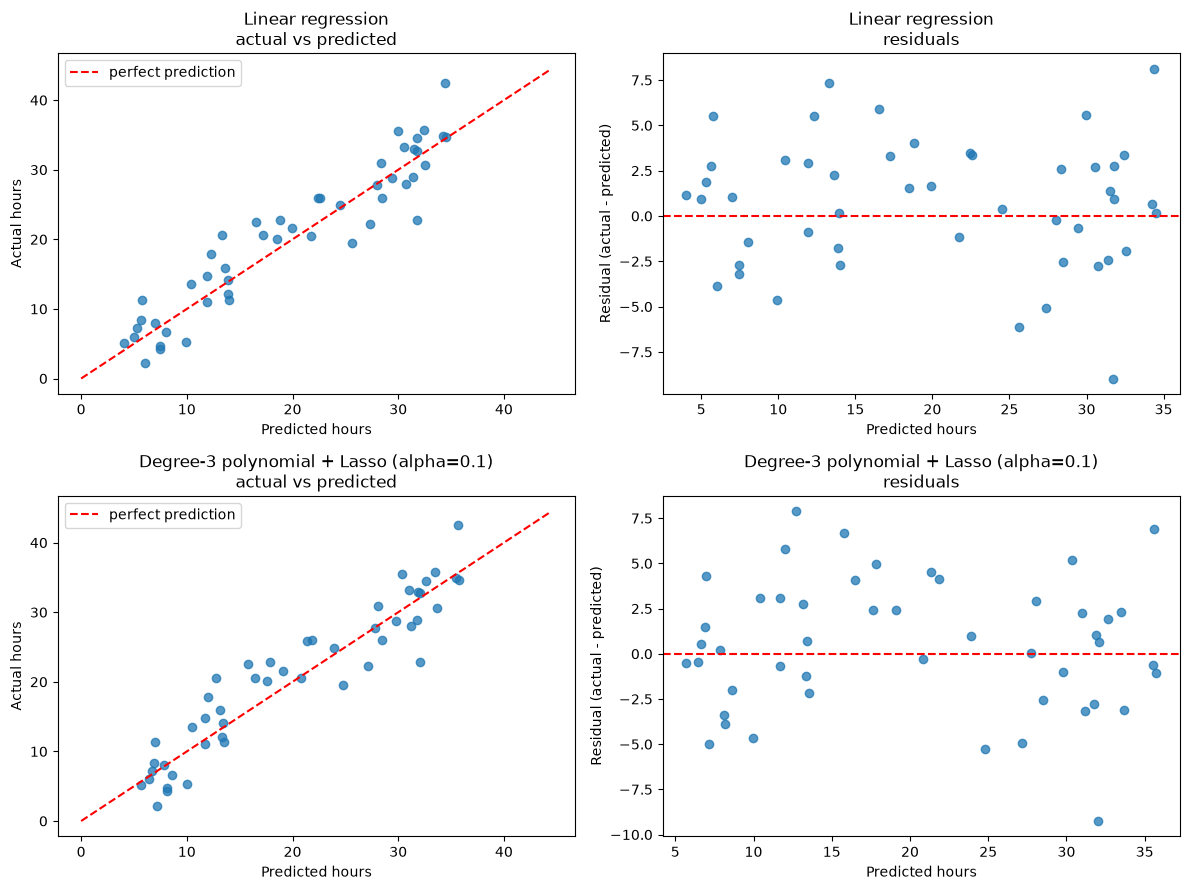

Residual std, shorter predictions: 3.43
Residual std, longer predictions: 3.81
Largest misses (predicted, actual, residual):
  31.7 predicted, 22.8 actual, residual -9.0
  34.4 predicted, 42.5 actual, residual 8.1
  13.3 predicted, 20.6 actual, residual 7.3
  25.6 predicted, 19.5 actual, residual -6.1


In [9]:
# Task 8: observed vs predicted, and residuals, for two models on the TEST set.
# Residual = actual - predicted. A decent fit is scattered around 0, with no bend
# and a spread that stays roughly steady.

lin_model = LinearRegression().fit(X_train, y_train)
lasso3_model = make_pipeline(
    PolynomialFeatures(3, include_bias=False),
    StandardScaler(),
    Lasso(alpha=poly3_chosen["Lasso"], max_iter=100000),
).fit(X_train, y_train)

models_to_plot = {
    "Linear regression": lin_model,
    f"Degree-3 polynomial + Lasso (alpha={poly3_chosen['Lasso']})": lasso3_model,
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for row, (name, model) in enumerate(models_to_plot.items()):
    pred = model.predict(X_test)
    observed = y_test.to_numpy()
    resid = observed - pred

    ax = axes[row, 0]
    ax.scatter(pred, observed, alpha=0.75)
    lims = [0, max(observed.max(), pred.max()) + 2]
    ax.plot(lims, lims, color="red", linestyle="--", label="perfect prediction")
    ax.set_xlabel("Predicted hours")
    ax.set_ylabel("Actual hours")
    ax.set_title(name + "\nactual vs predicted")
    ax.legend()

    ax = axes[row, 1]
    ax.scatter(pred, resid, alpha=0.75)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_xlabel("Predicted hours")
    ax.set_ylabel("Residual (actual - predicted)")
    ax.set_title(name + "\nresiduals")

plt.tight_layout()
plt.show()

# A few numbers to go with the linear residual plot.
pred = lin_model.predict(X_test)
observed = y_test.to_numpy()
resid = observed - pred
order = np.argsort(pred)
third = len(pred) // 3
print("Residual std, shorter predictions:", round(float(resid[order[:third]].std()), 2))
print("Residual std, longer predictions:", round(float(resid[order[-third:]].std()), 2))
print("Largest misses (predicted, actual, residual):")
for i in np.argsort(np.abs(resid))[::-1][:4]:
    print(f"  {pred[i]:.1f} predicted, {observed[i]:.1f} actual, residual {resid[i]:.1f}")

### What the plots show

I plotted linear regression and the degree-3 Lasso (the alpha CV picked, 0.1) on the 48 test tickets.

Both clouds sit near the diagonal, which fits an R2 around 0.88. They look almost the same, so the extra polynomial terms are not fixing a shape the line missed.

Residuals sit around 0. I don't see a U-shape. The spread is fairly steady. It is a bit wider on the longer predictions (residual std about 3.8, against about 3.4 on the shorter ones), so the misses in hours are slightly bigger for the long tickets, but I would not call it a funnel.

A few tickets are off by 7 to 9 hours. One was predicted around 32 hours and took about 23. The longest ticket in the file, 42.5 hours, was predicted around 34, short by about 8 hours. With only 48 test rows these points don't run the fit, but I would not use the model to promise a deadline. The plots are a rough check, not a proof.

## Task 9: Comparison and recommendation

In [10]:
# Every model evaluated above, test metrics only.
comparison = pd.DataFrame(results).round(3)
comparison

,model,MAE,RMSE,R2
0,Mean baseline,9.114,10.598,-0.021
1,Linear regression,2.906,3.572,0.884
2,Polynomial (degree 2),3.020,3.741,0.873
3,Polynomial (degree 3),3.140,3.949,0.858
4,Ridge,2.906,3.572,0.884
5,Lasso,2.906,3.572,0.884
6,"Ridge, degree 3",3.009,3.732,0.873
7,"Lasso, degree 3",2.942,3.644,0.879


**Q11. Lowest MAE and lowest RMSE?**

Linear regression, Ridge (alpha 0.1) and Lasso (alpha 0.001) tie for both: MAE 2.906 and RMSE 3.572. The rest of the order is the same under both metrics. Lasso degree 3, then Ridge degree 3, then polynomial degree 2, then polynomial degree 3, then the baseline.

They don't have to agree. MAE treats every hour the same. RMSE squares the errors first, so one model can look fine on MAE and worse on RMSE if it has a couple of large misses. Here the models don't have very different miss patterns, so the ranking comes out the same.

**Q15. Leakage**

`lines_changed` is the one I was most worried about. It counts lines edited during the fix, so it is not known when the ticket arrives, and it correlates about 0.85 with `resolution_hours`. Keeping it would inflate the score. `reopened` has the same timing problem. I dropped both, and `ticket_id`, and trained on `complexity_score` and `team_experience_years` only. The write-up in task 2 is the same decision.

**Q16. Would a random split still be ok?**

Not if the tickets covered several years, or the same teams kept showing up.

A random split can put a later ticket in training and an earlier one in test. In real use you only have the past, and the way tickets get solved changes over time. I would train on older tickets and test on newer ones.

If the same team is on both sides, the model can pick up that team's habits and look better than it would on a team it has never seen. A group split (for example GroupKFold by team or customer) is the fairer check. This file has no date and no team id, so I couldn't do either one here.

**Q17. What else before this was used for real?**

- A time-based check on newer tickets, and a check on teams that were held out.
- Error broken out by complexity. The long tickets were the ones it missed.
- A range around the prediction, not a single number of hours. A few tickets are off by most of a working day.
- Whether different people give the same `complexity_score`. The model leans on that column.
- A comparison with the estimate a person would make today, then a trial where the model is visible but nobody is booked against it.
- Real tickets. This file is synthetic, so 2.9 hours of error is not a promise about a real queue.

### Which model I would use

Ordinary linear regression on `complexity_score` and `team_experience_years`.

It cuts the average error from 9.1 hours to 2.9, with R2 0.88 on the test set. Degree 2's cross-validation edge was about 0.04 hours and degree 3 was worse. Ridge and Lasso on the same two columns give the same test error, and on the degree-3 model they only recover part of the damage from the extra terms. The residual plot has no curve. When the errors tie, I would rather explain two slopes: about 3.08 hours per complexity point, and about 0.32 hours off per year of experience.

Ridge with alpha 0.1 is the same answer if a penalty has to be in the pipeline. I would not expect a different prediction.

What still worries me: the data is made up, the test set is 48 tickets so small gaps between models are not a result, `complexity_score` is someone's judgment, the split is random, and some long tickets are off by 7 to 9 hours. I would not use it to set a hard deadline.

In [11]:
# Recompute the linear metrics by hand, as a check on the sklearn numbers.
pred = lin.predict(X_test)
error = y_test.to_numpy() - pred

mae = np.abs(error).mean()
mse = (error ** 2).mean()
rmse = np.sqrt(mse)
ss_tot = ((y_test.to_numpy() - y_test.mean()) ** 2).sum()
r2 = 1 - (error ** 2).sum() / ss_tot

print(f"Mean error: {error.mean():.3f}")
print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2:   {r2:.3f}")

Mean error: 0.699
MAE:  2.906
MSE:  12.761
RMSE: 3.572
R2:   0.884
